# Chapter 91: Cultural Transmission, Persistence, and Economic Change

This notebook reruns four of the chapter's stated hypotheticals: habits that lag practice, moral terms in an investment choice, family and institutional transmission, and the survival of tradition. Every number is a hypothetical teaching number, not historical data; a few extra input values are added.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def stacked_bar(ax, names, parts, part_labels, colors=None, ylabel="Value", total_marker=True, fmt=None):
    """Bars built from signed parts (one list per part), with a marker at each bar's net total.

    Positive parts stack upward from zero and negative parts downward, so a bar with a
    negative substitution part and a positive income part shows both pieces and the net.
    """
    parts = [[float(v) for v in p] for p in parts]
    n = len(names)
    xs = np.arange(n)
    colors = colors or [color(i) for i in range(len(parts))]
    pos_base, neg_base = np.zeros(n), np.zeros(n)
    for p, lab, col in zip(parts, part_labels, colors):
        p = np.array(p)
        base = np.where(p >= 0, pos_base, neg_base)
        ax.bar(xs, p, bottom=base, color=color(col), width=0.55, label=lab)
        pos_base = pos_base + np.where(p >= 0, p, 0)
        neg_base = neg_base + np.where(p < 0, p, 0)
    totals = np.sum(np.array(parts), axis=0)
    if total_marker:
        ax.scatter(xs, totals, marker="D", s=46, color=PALETTE["ink"], zorder=5)
        for x, t in zip(xs, totals):
            ax.annotate(f"net {fmt(t) if fmt else f'{t:,.2f}'}", (x, t), xytext=(14, 0), textcoords="offset points",
                        ha="left", va="center", fontsize=LABEL_SIZE,
                        bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(xs, names)
    ax.set_xlim(-0.6, n - 0.4 + 0.5)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def partial_adjustment_path(h0, alpha, x_path):
    """Habit path h_{t+1} = (1 - alpha) h_t + alpha x_t; returns [h_0, h_1, ...].

    Principle: institutional-habits-and-cumulative-adaptation (chapter 91). Book: h0 = 0,
    alpha = 0.25, x = (0.20, 0.80, 0.80, 0.80) gives 0.05, 0.2375, 0.3781, 0.4836; with
    x_1 = 0.20 instead, h_2 = 0.0875.
    """
    h = [h0]
    for x in x_path:
        h.append((1 - alpha) * h[-1] + alpha * x)
    return h


def plan_score(current, beta, future, extras=0.0):
    """Discounted plan score current + beta x future + extras (moral or stewardship terms).

    Part 10 helper for chapter 91. Principle: protestant-ethic-mechanism. Book: 70 + 0.50(30) = 85;
    40 + 0.50(78) = 79; with moral terms 85 - 10 = 75 and 79 + 5 = 84; 40 + 0.50(55) + 5 = 72.5.
    """
    return current + beta * future + extras


def cultural_transmission(x, tauA, tauB, exposure=0.0):
    """Bisin-Verdier step: P(A|A) = tauA + (1 - tauA) x, P(A|B) = (1 - tauB) x,
    x' = x P(A|A) + (1 - x) P(A|B), then institutional exposure e: x'' = x' + e (1 - x').

    Principle: cultural-transmission (chapter 91). Book: x = 0.30, tauA 0.50, tauB 0.20 gives
    0.65, 0.24, 0.363; tauA 0.80 gives 0.426; exposure 0.40 on 0.363 gives 0.6178.
    """
    paa = tauA + (1 - tauA) * x
    pab = (1 - tauB) * x
    fam = x * paa + (1 - x) * pab
    return {"P_AA": paa, "P_AB": pab, "family": fam, "next": fam + exposure * (1 - fam)}


def cultural_persistence_share(beta, kappa, Delta):
    """Traditionalist share x* = (kappa - Delta beta) / (kappa (1 - Delta)), zero once Delta > kappa / beta.

    Principle: cultural-persistence (chapter 91). Book: beta 60, kappa 18: 0.741 at 0.10,
    0.222 at 0.25, 0 at 0.35; threshold 0.30. Returns x_star, the raw formula value and threshold.
    """
    raw = (kappa - Delta * beta) / (kappa * (1 - Delta))
    return {"x_star": max(0.0, raw), "raw": raw, "threshold": kappa / beta}


plt.rcParams.update(HOUSE_RC)


behavioral = SimpleNamespace(partial_adjustment_path=partial_adjustment_path, cultural_transmission=cultural_transmission, cultural_persistence_share=cultural_persistence_share)


labor = SimpleNamespace(plan_score=plan_score)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'institutional-habits-and-cumulative-adaptation': {'h0': 0,
                                                    'x0': 0.2,
                                                    'x': 0.8,
                                                    'alpha': 0.25,
                                                    'h': (0.05, 0.2375, 0.3781, 0.4836),
                                                    'h2_revert': 0.0875},
 'protestant-ethic-mechanism': {'beta': 0.5,
                                'consume': (70, 30),
                                'invest_now': 40,
                                'cost': 60,
                                'payoff': 78,
                                'penalty': 10,
                                'steward': 5,
                                'mara_consume': 85,
                                'mara_invest': 79,
                                'elias_consume': 75,
                                'elias_invest': 84,
                                'net': 18,
                                'payoff_low': 55,
                                'elias_invest_low': 72.5},
 'cultural-transmission': {'x': 0.3,
                           'tauA': 0.5,
                           'tauB': 0.2,
                           'P_AA': 0.65,
                           'P_AB': 0.24,
                           'next': 0.363,
                           'tauA_hi': 0.8,
                           'next_hi': 0.426,
                           'exposure': 0.4,
                           'next_exposed': 0.6178},
 'cultural-persistence': {'beta': 60,
                          'kappa': 18,
                          'x_010': 0.741,
                          'x_025': 0.222,
                          'x_035': 0,
                          'threshold': 0.3},
 'constructed': {'institutional-habits-and-cumulative-adaptation': {'alpha': [0.5], 'x': [0.5]},
                 'protestant-ethic-mechanism': {'payoff': [90]},
                 'cultural-transmission': {'tauB': [0.5]},
                 'cultural-persistence': {'kappa': [24]}}}


LABEL = "Hypothetical teaching numbers, not historical data."


def habit_picture(alpha=0.25, x=0.80):
    xs = [0.20] + [x] * 7
    h = behavioral.partial_adjustment_path(0.0, alpha, xs)
    t = np.arange(len(h))
    fig, ax = new_figure()
    ax.step(np.arange(len(xs) + 1), xs + [x], where="post", color=PALETTE["gold"], linewidth=2, linestyle="dashed")
    ax.plot(t, h, color=PALETTE["teal"], marker="o", linewidth=2.2)
    label(ax, 7, x, "practice x_t", col="gold", dx=-4, dy=6, ha="right")
    for k in (1, 2, 3, 4):
        label(ax, k, h[k], num(h[k], 4), col="teal", dx=6, dy=-6 if h[k] > 0.12 else 6, va="top" if h[k] > 0.12 else "bottom")
    ax.set_xlim(-0.3, 8.6)
    ax.set_ylim(0, 1.0)
    ax.set_xlabel("Period t")
    ax.set_ylabel("Share with the habit h_t")
    a1 = 1 - alpha
    metrics = {"h_1": num(h[1], 4), "h_2": num(h[2], 4), "h_3": num(h[3], 4), "h_4": num(h[4], 4),
               "Gap to practice at t = 4": num(x - h[4], 4)}
    steps = [f"h_1 = {num(a1)}(0) + {num(alpha)}(0.20) = {num(h[1], 4)}",
             f"h_2 = {num(a1)}({num(h[1], 4)}) + {num(alpha)}({num(x)}) = {num(h[2], 4)}",
             f"h_3 = {num(a1)}({num(h[2], 4)}) + {num(alpha)}({num(x)}) = {num(h[3], 4)}",
             f"h_4 = {num(a1)}({num(h[3], 4)}) + {num(alpha)}({num(x)}) = {num(h[4], 4)}"]
    interp = (f"{LABEL} Practice is 0.20 in period 0 and {num(x)} afterwards. With updating speed {num(alpha)}, "
              f"h_2 = {num(a1)} x {num(h[1], 4)} + {num(alpha)} x {num(x)} = {num(h[2], 4)}, and by period 4 the habit "
              f"is {num(h[4], 4)}, still {num(x - h[4], 4)} below current practice.")
    alt = (f"Habit share rising from 0 toward practice {num(x)}: {num(h[1], 4)}, {num(h[2], 4)}, {num(h[3], 4)}, "
           f"{num(h[4], 4)} in periods 1 to 4.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def ethic_picture(moral="on", payoff=78):
    b = BV["protestant-ethic-mechanism"]
    on = moral == "on"
    cons = labor.plan_score(70, b["beta"], 30, -b["penalty"] if on else 0.0)
    inv = labor.plan_score(40, b["beta"], payoff, b["steward"] if on else 0.0)
    fig, ax = new_figure()
    pick = "invest" if inv > cons else ("consume" if cons > inv else "tie")
    cols = ["navy" if pick == "consume" else "grey", "teal" if pick == "invest" else "grey"]
    if pick == "tie":
        cols = ["navy", "teal"]
    bar_compare(ax, ["Spend 70, carry 30", "Spend 40, buy machine"], [cons, inv], colors=cols,
                value_labels=[num(cons, 1), num(inv, 1)], ylabel="Plan score", xlabel="Plan")
    ax.set_ylim(0, 112)
    who = "Elias (moral terms on)" if on else "Mara (no moral terms)"
    if pick == "tie":
        verdict = f"the two plans tie at {num(inv, 1)} and the owner is indifferent"
    elif pick == "invest":
        verdict = f"investing wins, {num(inv, 1)} against {num(cons, 1)}"
    else:
        verdict = f"the consumption-heavy plan wins, {num(cons, 1)} against {num(inv, 1)}"
    cons_line = f"70 + 0.50(30){' - 10' if on else ''} = {num(cons, 1)}"
    inv_line = f"40 + 0.50({payoff}){' + 5' if on else ''} = {num(inv, 1)}"
    metrics = {"Consume plan score": num(cons, 1), "Invest plan score": num(inv, 1),
               "Choice": {"invest": "Invest", "consume": "Consume", "tie": "Indifferent (tie)"}[pick]}
    steps = [f"Consume plan: {cons_line}", f"Invest plan: {inv_line}", f"Result: {verdict}"]
    interp = (f"{LABEL} For {who} with a machine payoff of {payoff}, the consume plan scores {cons_line} and the "
              f"invest plan {inv_line}, so {verdict}.")
    alt = f"Two bars: consume plan {num(cons, 1)} and invest plan {num(inv, 1)} for {who}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def transmission_picture(tau_a=0.50, tau_b=0.20, inst=0.0):
    x = BV["cultural-transmission"]["x"]
    r = behavioral.cultural_transmission(x, tau_a, tau_b, inst)
    fig, ax = new_figure()
    names = ["Parents x_t", "After family", "After institution"]
    vals = [x, r["family"], r["next"]]
    bar_compare(ax, names, vals, colors=["grey", "teal", "navy"], value_labels=[num(v, 4) for v in vals],
                ylabel="Share with trait A", xlabel="Stage")
    ax.set_ylim(0, 1.0)
    metrics = {"P(A | A)": num(r["P_AA"], 3), "P(A | B)": num(r["P_AB"], 3), "x_t+1 after family": num(r["family"], 4),
               "Share after institutional exposure": num(r["next"], 4)}
    steps = [f"P(A|A) = {num(tau_a)} + {num(1 - tau_a)}(0.30) = {num(r['P_AA'], 3)}",
             f"P(A|B) = {num(1 - tau_b)}(0.30) = {num(r['P_AB'], 3)}",
             f"x_t+1 = 0.30({num(r['P_AA'], 3)}) + 0.70({num(r['P_AB'], 3)}) = {num(r['family'], 4)}",
             f"With exposure: {num(r['family'], 4)} + {num(inst)}(1 - {num(r['family'], 4)}) = {num(r['next'], 4)}"]
    interp = (f"{LABEL} Starting from 30 percent, family transmission gives x_t+1 = 0.30 x {num(r['P_AA'], 3)} + "
              f"0.70 x {num(r['P_AB'], 3)} = {num(r['family'], 4)}. Institutional exposure of {num(inst)} then "
              f"brings the share to {num(r['next'], 4)}.")
    alt = (f"Three bars: 0.30 among parents, {num(r['family'], 4)} after family transmission and {num(r['next'], 4)} "
           f"after institutional exposure.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def persistence_picture(delta=0.10, kappa=18):
    beta = BV["cultural-persistence"]["beta"]
    r = behavioral.cultural_persistence_share(beta, kappa, delta)
    xs, thr, raw = r["x_star"], r["threshold"], r["raw"]
    grid = np.linspace(0, 0.5, 201)
    curve = [behavioral.cultural_persistence_share(beta, kappa, d)["x_star"] for d in grid]
    fig, ax = new_figure()
    ax.plot(grid, curve, color=PALETTE["teal"], linewidth=2.2)
    vline(ax, thr, f"kappa / beta = {num(thr)}", col="terracotta", y_frac=0.95, ha="right")
    mark(ax, delta, xs, f"x* = {num(xs, 3)}", col="navy", dx=8, dy=6)
    ax.set_xlim(0, 0.55)
    ax.set_ylim(-0.05, 1.12)
    ax.set_xlabel("Environmental instability Delta")
    ax.set_ylabel("Traditionalist share x*")
    num_ = kappa - delta * beta
    den = kappa * (1 - delta)
    if raw > 0:
        verdict = f"a traditionalist share of {num(xs, 3)} survives"
    else:
        verdict = "the numerator is not positive, so no traditionalists survive (x* = 0)"
    metrics = {"x*": num(xs, 3), "Threshold kappa / beta": num(thr), "Numerator kappa - Delta beta": num(num_, 1)}
    steps = [f"Numerator: {kappa} - {num(delta)}({beta}) = {num(num_, 1)}",
             f"Denominator: {kappa}({num(1 - delta)}) = {num(den, 1)}",
             f"x* = {num(num_, 1)} / {num(den, 1)} = {num(raw, 3)}" + ("" if raw > 0 else ", so x* = 0"),
             f"Threshold: {kappa} / {beta} = {num(thr)}"]
    interp = (f"{LABEL} With learning cost {kappa} and instability {num(delta)}, x* = ({kappa} - {num(delta)} x {beta}) "
              f"/ ({kappa} x {num(1 - delta)}) = {num(num_, 1)} / {num(den, 1)}, so {verdict}. Tradition disappears "
              f"once instability passes {kappa} / {beta} = {num(thr)}.")
    alt = (f"Traditionalist share falling with instability and hitting zero at {num(thr)}; at Delta = {num(delta)} "
           f"the share is {num(xs, 3)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Institutional habits: habits lag practice

Practice is 0.20 in period 0, then 0.80; habit updates at speed 0.25.

$$h_{t+1}=(1-\alpha)h_t+\alpha x_t, \qquad h_2=0.75(0.05)+0.25(0.80)=0.2375$$

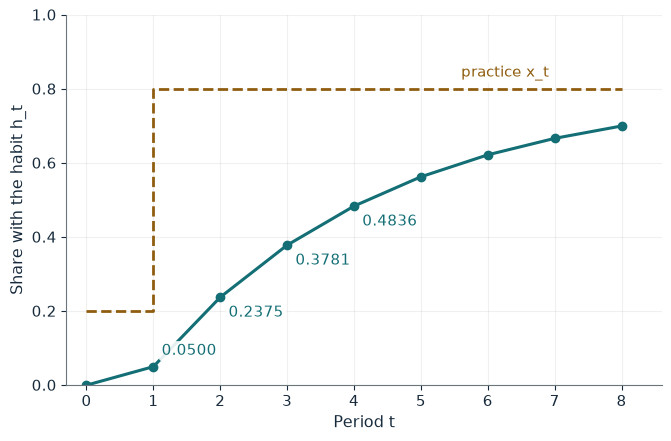

h_1                       0.0500
h_2                       0.2375
h_3                       0.3781
h_4                       0.4836
Gap to practice at t = 4  0.3164

Worked steps:
  1. h_1 = 0.75(0) + 0.25(0.20) = 0.0500
  2. h_2 = 0.75(0.0500) + 0.25(0.80) = 0.2375
  3. h_3 = 0.75(0.2375) + 0.25(0.80) = 0.3781
  4. h_4 = 0.75(0.3781) + 0.25(0.80) = 0.4836

Hypothetical teaching numbers, not historical data. Practice is 0.20 in period 0 and 0.80 afterwards. With updating speed 0.25, h_2 = 0.75 x 0.0500 + 0.25 x 0.80 = 0.2375, and by period 4 the habit is 0.4836, still 0.3164 below current practice.


In [2]:
show(habit_picture(alpha=0.25, x=0.80))

Change one input, `x`, and hold the others at the book's values:

In [3]:
sweep(habit_picture, 'x', [0.2, 0.5, 0.8], {'alpha': 0.25}, ['h_2', 'h_4'])

x | h_2 | h_4
0.2 | 0.0875 | 0.1367
0.5 | 0.1625 | 0.3102
0.8 | 0.2375 | 0.4836


With practice at 0.80 the habit reaches only 0.4836 by period 4; if practice reverts to 0.20, h_2 is 0.0875.

## 2. Protestant ethic mechanism: moral terms and the investment choice

100 discretionary units; a machine costs 60 and pays 78 next year; discount 0.50.

$$70+0.50(30)=85, \qquad 40+0.50(78)=79$$

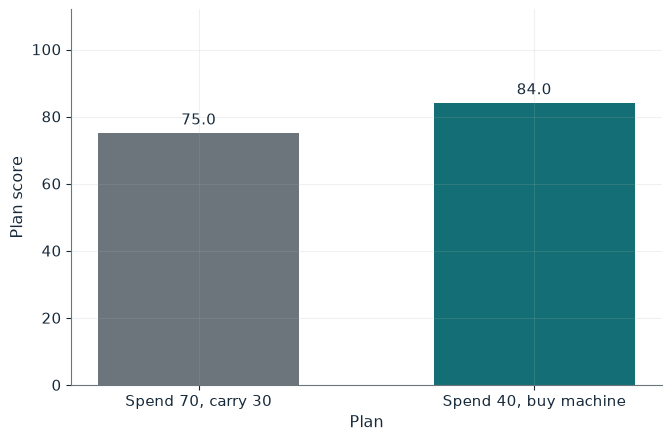

Consume plan score  75.0
Invest plan score   84.0
Choice              Invest

Worked steps:
  1. Consume plan: 70 + 0.50(30) - 10 = 75.0
  2. Invest plan: 40 + 0.50(78) + 5 = 84.0
  3. Result: investing wins, 84.0 against 75.0

Hypothetical teaching numbers, not historical data. For Elias (moral terms on) with a machine payoff of 78, the consume plan scores 70 + 0.50(30) - 10 = 75.0 and the invest plan 40 + 0.50(78) + 5 = 84.0, so investing wins, 84.0 against 75.0.


In [4]:
show(ethic_picture(moral='on', payoff=78))

Change one input, `payoff`, and hold the others at the book's values:

In [5]:
sweep(ethic_picture, 'payoff', [55, 78, 90], {'moral': 'on'}, ['Consume plan score', 'Invest plan score', 'Choice'])

payoff | Consume plan score | Invest plan score | Choice
55 | 75.0 | 72.5 | Consume
78 | 75.0 | 84.0 | Invest
90 | 75.0 | 90.0 | Invest


Moral terms turn 85 against 79 into 75 against 84, so Elias invests; at a payoff of 55 he does not.

## 3. Cultural transmission: family versus institutional transmission

30 percent of parents hold trait A; tau_A = 0.50, tau_B = 0.20.

$$x_{t+1}=x_tP(A\mid A)+(1-x_t)P(A\mid B), \qquad x_{t+1}=0.30(0.65)+0.70(0.24)=0.363$$

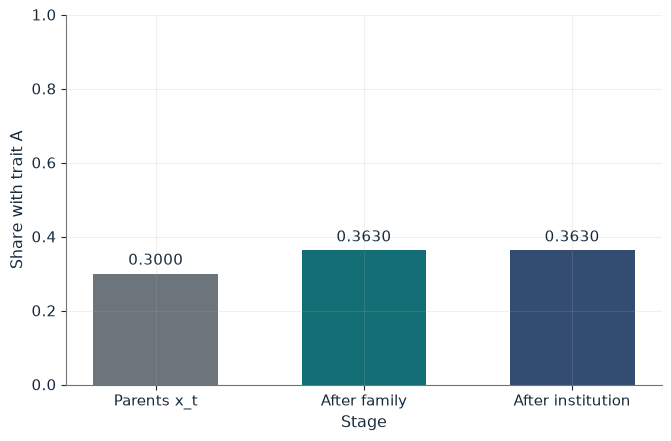

P(A | A)                            0.650
P(A | B)                            0.240
x_t+1 after family                  0.3630
Share after institutional exposure  0.3630

Worked steps:
  1. P(A|A) = 0.50 + 0.50(0.30) = 0.650
  2. P(A|B) = 0.80(0.30) = 0.240
  3. x_t+1 = 0.30(0.650) + 0.70(0.240) = 0.3630
  4. With exposure: 0.3630 + 0.00(1 - 0.3630) = 0.3630

Hypothetical teaching numbers, not historical data. Starting from 30 percent, family transmission gives x_t+1 = 0.30 x 0.650 + 0.70 x 0.240 = 0.3630. Institutional exposure of 0.00 then brings the share to 0.3630.


In [6]:
show(transmission_picture(tau_a=0.50, tau_b=0.20, inst=0.0))

Change one input, `inst`, and hold the others at the book's values:

In [7]:
sweep(transmission_picture, 'inst', [0.0, 0.4], {'tau_a': 0.5, 'tau_b': 0.2}, ['x_t+1 after family', 'Share after institutional exposure'])

inst | x_t+1 after family | Share after institutional exposure
0.0 | 0.3630 | 0.3630
0.4 | 0.3630 | 0.6178


Family transmission alone moves the share to 0.363; 40 percent institutional exposure lifts it to 0.6178.

## 4. Cultural persistence: when does tradition survive?

Correct-action payoff 60, learning cost 18.

$$x^*=\frac{\kappa-\Delta\beta}{\kappa(1-\Delta)}, \qquad \Delta\leq\frac{\kappa}{\beta}$$

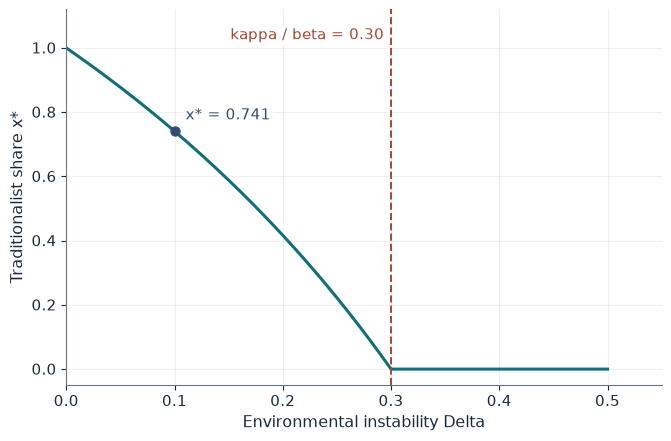

x*                            0.741
Threshold kappa / beta        0.30
Numerator kappa - Delta beta  12.0

Worked steps:
  1. Numerator: 18 - 0.10(60) = 12.0
  2. Denominator: 18(0.90) = 16.2
  3. x* = 12.0 / 16.2 = 0.741
  4. Threshold: 18 / 60 = 0.30

Hypothetical teaching numbers, not historical data. With learning cost 18 and instability 0.10, x* = (18 - 0.10 x 60) / (18 x 0.90) = 12.0 / 16.2, so a traditionalist share of 0.741 survives. Tradition disappears once instability passes 18 / 60 = 0.30.


In [8]:
show(persistence_picture(delta=0.10, kappa=18))

Change one input, `delta`, and hold the others at the book's values:

In [9]:
sweep(persistence_picture, 'delta', [0.1, 0.25, 0.35], {'kappa': 18}, ['x*'])

delta | x*
0.1 | 0.741
0.25 | 0.222
0.35 | 0.000


The traditionalist share is 0.741 at Delta 0.10, 0.222 at 0.25 and zero beyond the 0.30 threshold.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

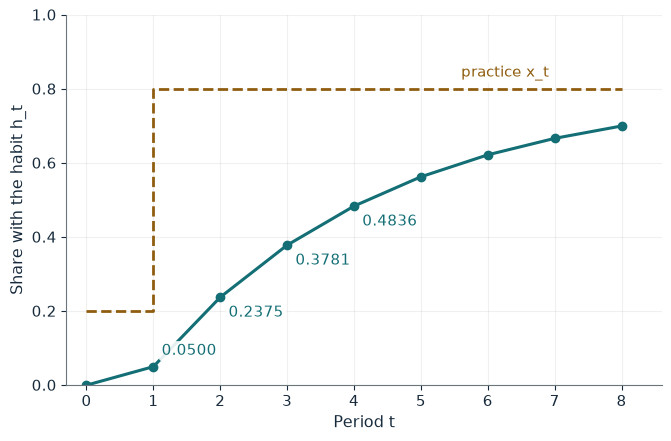

h_1                       0.0500
h_2                       0.2375
h_3                       0.3781
h_4                       0.4836
Gap to practice at t = 4  0.3164

Worked steps:
  1. h_1 = 0.75(0) + 0.25(0.20) = 0.0500
  2. h_2 = 0.75(0.0500) + 0.25(0.80) = 0.2375
  3. h_3 = 0.75(0.2375) + 0.25(0.80) = 0.3781
  4. h_4 = 0.75(0.3781) + 0.25(0.80) = 0.4836

Hypothetical teaching numbers, not historical data. Practice is 0.20 in period 0 and 0.80 afterwards. With updating speed 0.25, h_2 = 0.75 x 0.0500 + 0.25 x 0.80 = 0.2375, and by period 4 the habit is 0.4836, still 0.3164 below current practice.


In [10]:
show(habit_picture(alpha=0.25, x=0.80))

## Practice

**1.** With alpha = 0.50 and practice 0.50 after period 0, what is h_2?

<details><summary>Answer</summary>

h_1 = 0.10; h_2 = 0.5 x 0.10 + 0.5 x 0.50 = 0.30.

</details>

**2.** With tau_A = 0.80 and no exposure, what is x_t+1?

<details><summary>Answer</summary>

0.30 x (0.80 + 0.20 x 0.30) + 0.70 x 0.24 = 0.258 + 0.168 = 0.426.

</details>

**3.** With kappa = 24 and Delta = 0.35, what is x*?

<details><summary>Answer</summary>

(24 - 21) / (24 x 0.65) = 3 / 15.6 = 0.192.

</details>